In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
# import pytorch_lightning as pl
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *


import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

In [2]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

# load model
model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

strong_bound_df = pd.read_csv(os.path.join(model_dir, 'final_nc14_boundaries_df.bound_score_gt_1.csv'))


chrom, start, end = "chr2R", 10879601, 10879800
row = strong_bound_df.query('chrom == @chrom and start == @start and end==@end and direction == "+"')

resolution=200
num_merged=11
delta=2
ws=1

fc dim 206
extra dim 6


In [3]:
def get_true_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    ins_score_context_bin_width=10
    idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
    y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    
    demeaned_y1_pos = y_pos - np.mean(y_pos, axis=1)[:, np.newaxis]
    middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width]

    
    x, y = np.arange(len(middle_points1_pos)), middle_points1_pos
    return x, y

import pysam
from domino.utils.tools import seq_from_df
def get_predicted_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')

    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]

    genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations//dm6.fa'
    genome_fasta = pysam.FastaFile(genome_path)
    
    locus_df['direction'] = ["+"] * len(locus_df)
    locus_df.reset_index(inplace=True, drop=True)
    seqs = seq_from_df(genome_fasta, locus_df, DNA_context_length=16*200)
    
    predictions = model(seqs.to('cuda'))
    predictions = predictions.cpu().detach().flatten()
    
    x, y = np.arange(len(predictions)), predictions
    return x, y
    
def save_track(y, boundary, fn, resolution=200, offset=20_000):
    chrom, start, end = boundary
    df = pd.DataFrame({
        'chrom': [chrom] * len(y),
        'start': np.arange(start - offset, end + offset, resolution),
        'end': np.arange(start - offset, end + offset, resolution) + resolution,
        'value': y
    })
    # Save to BEDGraph
    df.to_csv(fn, sep='\t', header=False, index=False)
    return df

In [4]:
# boundary = ("chr2R", 10879601, 10879800)

# _, obs_y = get_true_track(boundary)
# _, pred_y = get_predicted_track(boundary)

# obs_df = save_track(obs_y, boundary, 'observed.bedGraph')
# pred_df = save_track(pred_y, boundary, 'predicted.bedGraph')

In [4]:
all_nc14_boundaries = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv').drop_duplicates(['chrom', 'start', 'end'])[['chrom', 'start', 'end']]

midpoints = (all_nc14_boundaries['start'] + all_nc14_boundaries['start']) // 2
all_nc14_boundaries['start'] = midpoints
all_nc14_boundaries['end'] = midpoints
all_nc14_boundaries['dot'] = ['.'] * len(all_nc14_boundaries)
all_nc14_boundaries['ins'] = [0] * len(all_nc14_boundaries)
all_nc14_boundaries['sign'] = ['+'] * len(all_nc14_boundaries)

# all_nc14_boundaries.to_csv('all_nc14_boundaries.bed', sep='\t', index=False, header=False)

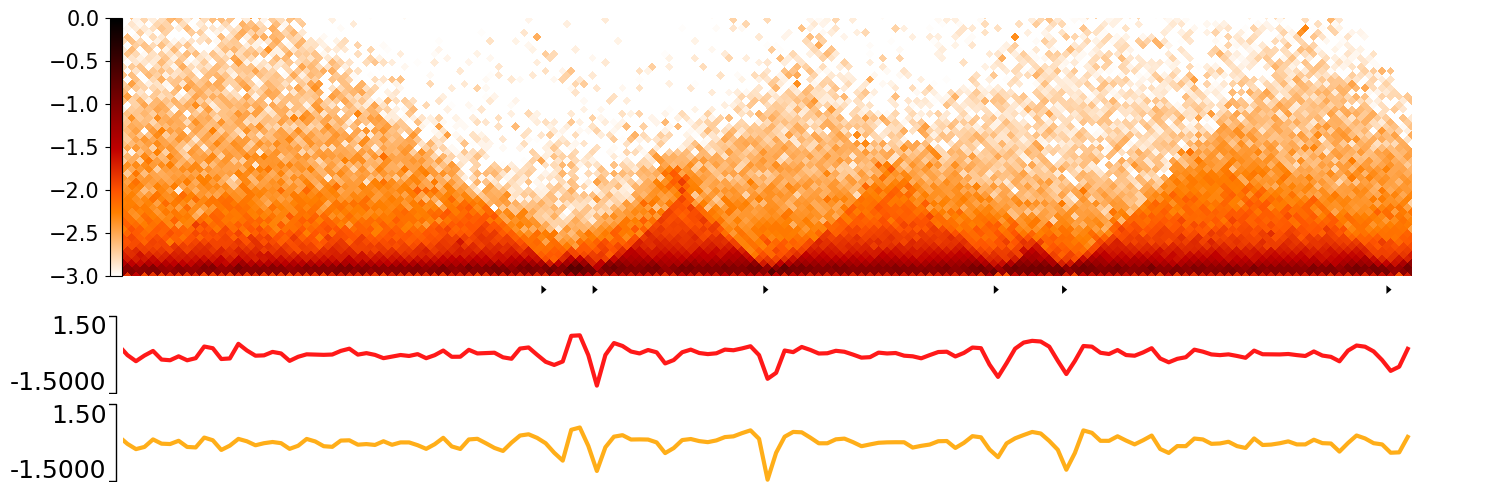

In [5]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
BOUND_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/boundaries/'
RESOLUTION=200
NUM_MERGED=11

chrom, start, end = "chr2R", 10879601, 10879800

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.4, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3, 
    grid=False,
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=2,
    style='line',
    line_width=3,
    alpha=0.9,
    border_color=None,
    properties=dict(fontsize=16),
)

BED_KWARGS = dict(
    border_only=False,
    labels=False,
    num_rows=1,
    linewidth=0,
    height=0.5,
    properties=dict(line_width=5, fontsize=16),
    border_color=None,
    marker='s',
    
)

frame = [
    # coolbox.api.XAxis(fontsize=18, show_chrom=True),

    # Map
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),

    # Boundaries
    coolbox.api.BED(f"all_nc14_boundaries.bed", color='k',  **BED_KWARGS),
    # coolbox.api.BED(f"{BOUND_DATA_DIR}/nc14_embryo_merged_all_11.resolution=200bp.delta=2.window_size=1kb.boundaries.bed", color='black', title='Boundares', **BED_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    
    # Insulation tracks
    coolbox.api.BedGraph('observed.bedGraph', max_value=1.5, min_value=-1.5, color='red', **BEDGRAPH_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    coolbox.api.BedGraph('predicted.bedGraph', max_value=1.5, min_value=-1.5, color='orange', **BEDGRAPH_KWARGS)
]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-15_000}-{end + 15_000}")
fig.set(facecolor="white")
# fig.savefig("plots/fig2a_strong_pred_locus.pdf", format="pdf", dpi=300, bbox_inches='tight')
display(fig)

In [6]:
def plot_weights(array, ax, pattern_name, num_seqlets):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    plt.ylim(min(df.sum(axis=1).min(), 0), df.sum(axis=1).max())
    ax.set_title(f'{pattern_name} (num_seqlets={num_seqlets})')

In [7]:
resolution=200
num_merged=11
delta=2
ws=1

DNA_context_bin_width=16
DNA_context_length = 200*DNA_context_bin_width

genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
data = fanc.load(f'{data_dir}/mcools/new_nc14_embryo_merged_all_{num_merged}.mcool@{resolution}')

X = seq_from_df(genome_fasta, strong_bound_df, DNA_context_length)

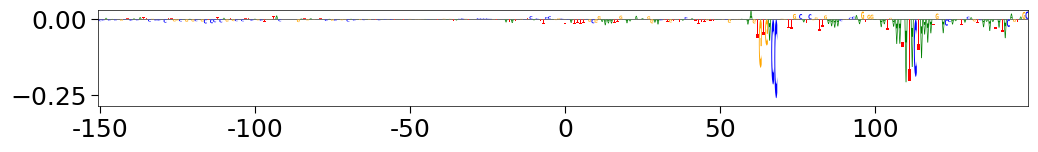

In [16]:
from tangermeme.ism import saturation_mutagenesis
from tangermeme.plot import plot_logo

SEQ_IDX = 14008
flanking_context=50
start = 3050
end = 3350

attr = saturation_mutagenesis(model, X[SEQ_IDX].unsqueeze(0), device='cuda:0', start=start, end=end)

fig, ax = plt.subplots(2, 1, figsize=(12, 1.25))
ax = plt.subplot(111)
logo = plot_logo(attr[0], ax=ax)
ax.axhline(0, color='w', linewidth=0.3)  # Alternatively, make the line white
ax.grid(False)
ax.set_xticklabels(np.arange(-200, 199, 50))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

    
row = strong_bound_df.iloc[SEQ_IDX]
plt.ylim([attr.min() * 1.1, attr.max() * 1.1])
# fig.savefig("plots/fig2a_attr.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

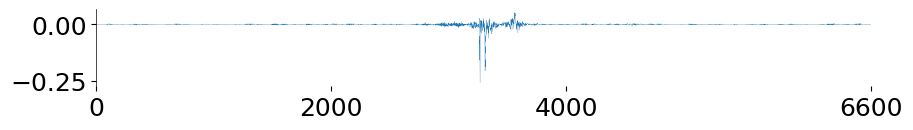

In [17]:
attr = saturation_mutagenesis(model, X[SEQ_IDX].unsqueeze(0), device='cuda:0')
# sum of attribution 
attr_track = attr[0].sum(axis=0)

fig, ax = plt.subplots(figsize=(10, 1)) 
ax.plot(np.arange(6600), attr_track, linewidth=0.2)
ax.grid(False)
ax.set_xlim(0, 6600)
ax.spines['top'].set_visible(False)  # Hide the top spine  
ax.spines['bottom'].set_visible(False)  # Hide the top spine  
ax.spines['right'].set_visible(False)  # Hide the top spine 
for spine in ['left']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(0.5)  # Decrease spine thickness
ax.set_xticks([0, 2000, 4000, 6600])  # Hide x ticks  

# fig.savefig("plots/fig2a_ism.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()
